# Chương 2 — Python cho học máy

Notebook đi kèm giáo trình **Học máy cơ bản với Python** (Lê Nhật Tùng).

**Cách dùng trên Google Colab**

1. Mở <https://colab.research.google.com> → **File** → **Upload notebook** → chọn file này
   (hoặc mở từ Google Drive bằng *Open with → Google Colaboratory*).
2. Chạy lần lượt từng ô từ trên xuống bằng **Shift + Enter**. Các ô sau dùng lại biến của ô trước.
3. Gặp lỗi lạ: **Runtime → Restart session and run all**.

Mỗi ô mã bắt đầu bằng dòng `# ô ten_o` — đó là tên ô in ở đầu mỗi khung mã trong sách,
giúp bạn đối chiếu với giáo trình. Kết quả bên dưới mỗi ô là kết quả chạy mẫu; máy bạn có thể
khác rất nhỏ ở chữ số thập phân cuối nếu phiên bản thư viện khác.

> Hãy **tự gõ lại mã** vào một notebook trống trước khi xem lời giải ở đây — đó là cách học nhanh nhất.

> Chương này tải bộ dữ liệu bằng `seaborn.load_dataset(...)`, cần kết nối Internet (Colab luôn có sẵn).


## 2.2 Chuẩn bị môi trường làm việc

In [1]:
# ô kiem_tra_phien_ban
import sys
import numpy as np
import pandas as pd
import matplotlib
import sklearn
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 85)
print("Python      :", sys.version.split()[0])
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

Python      : 3.13.16
NumPy       : 2.5.3
pandas      : 3.0.5
Matplotlib  : 3.11.2
scikit-learn: 1.9.1


## 2.3 Ôn nhanh Python cơ bản

In [2]:
# ô py_list
diem = [7.5, 8.0, 6.5, 9.0, 5.5]          # danh sách (list) điểm của 5 sinh viên
print("Điểm đầu tiên:", diem[0])          # chỉ số bắt đầu từ 0
print("Điểm cuối cùng:", diem[-1])        # chỉ số âm: đếm từ cuối
print("Ba điểm đầu:", diem[0:3])          # cắt lát: từ vị trí 0 đến trước 3
print("Số sinh viên:", len(diem))

Điểm đầu tiên: 7.5
Điểm cuối cùng: 5.5
Ba điểm đầu: [7.5, 8.0, 6.5]
Số sinh viên: 5


In [3]:
# ô py_loop_ham
def xep_loai(d):
    """Trả về xếp loại học lực từ điểm số d."""
    if d >= 8.5:
        return "Giỏi"
    elif d >= 7.0:
        return "Khá"
    elif d >= 5.0:
        return "Trung bình"
    return "Yếu"

for d in diem:
    print(f"Điểm {d:4.1f} -> {xep_loai(d)}")

Điểm  7.5 -> Khá
Điểm  8.0 -> Khá
Điểm  6.5 -> Trung bình
Điểm  9.0 -> Giỏi
Điểm  5.5 -> Trung bình


In [4]:
# ô py_dict
sinh_vien = {"ten": "An", "tuoi": 20, "diem": 8.0}   # từ điển (dict): khóa -> giá trị
print(sinh_vien["ten"], "có điểm", sinh_vien["diem"])
sinh_vien["lop"] = "DS01"                             # thêm một cặp khóa-giá trị
print(sinh_vien)

An có điểm 8.0
{'ten': 'An', 'tuoi': 20, 'diem': 8.0, 'lop': 'DS01'}


In [5]:
# ô py_list_comp
binh_phuong = [x ** 2 for x in range(1, 6)]           # list comprehension
dat = [d for d in diem if d >= 7.0]                   # lọc điểm từ 7 trở lên
print(binh_phuong)
print(dat)

[1, 4, 9, 16, 25]
[7.5, 8.0, 9.0]


## 2.4 NumPy: tính toán với mảng

In [6]:
# ô np_tao_mang
a = np.array([1, 2, 3, 4])                    # mảng 1 chiều từ list
B = np.array([[1, 2, 3],
              [4, 5, 6]])                     # mảng 2 chiều (ma trận 2 x 3)
print("a =", a)
print("B =\n", B)
print("a.shape =", a.shape, "  B.shape =", B.shape)
print("Kiểu dữ liệu của B:", B.dtype)

a = [1 2 3 4]
B =
 [[1 2 3]
 [4 5 6]]
a.shape = (4,)   B.shape = (2, 3)
Kiểu dữ liệu của B: int64


In [7]:
# ô np_ham_tao
print(np.zeros(4))                    # 4 số 0
print(np.ones((2, 3)))                # ma trận 2 x 3 toàn số 1
print(np.arange(0, 10, 2))            # từ 0 đến trước 10, bước 2
print(np.linspace(0, 1, 5))           # 5 số cách đều từ 0 đến 1

[0. 0. 0. 0.]
[[1. 1. 1.]
 [1. 1. 1.]]
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]


In [8]:
# ô np_chi_so
M = np.array([[10, 20, 30],
              [40, 50, 60],
              [70, 80, 90]])
print("M[0, 1]   =", M[0, 1])         # dòng 0, cột 1
print("M[1]      =", M[1])            # cả dòng 1
print("M[:, 2]   =", M[:, 2])         # cả cột 2 (dấu : nghĩa là "tất cả")
print("M[0:2, 1:] =\n", M[0:2, 1:])   # dòng 0-1, cột 1 đến hết

M[0, 1]   = 20
M[1]      = [40 50 60]
M[:, 2]   = [30 60 90]
M[0:2, 1:] =
 [[20 30]
 [50 60]]


In [9]:
# ô np_phep_toan
x = np.array([1, 2, 3])
y = np.array([10, 20, 30])
print("x + y  =", x + y)              # cộng từng phần tử
print("x * y  =", x * y)              # nhân từng phần tử
print("x ** 2 =", x ** 2)             # bình phương từng phần tử
print("x * 10 =", x * 10)             # nhân mọi phần tử với 10

x + y  = [11 22 33]
x * y  = [10 40 90]
x ** 2 = [1 4 9]
x * 10 = [10 20 30]


In [10]:
# ô np_vong_lap_vs_vector
gia = [100, 250, 80, 40]
so_luong = [2, 1, 5, 10]
# Cách 1: vòng lặp Python thuần
tong = 0
for g, s in zip(gia, so_luong):
    tong += g * s
print("Tổng tiền (vòng lặp):", tong)
# Cách 2: NumPy "vector hóa" -- một dòng, nhanh hơn nhiều với dữ liệu lớn
print("Tổng tiền (NumPy)   :", np.sum(np.array(gia) * np.array(so_luong)))

Tổng tiền (vòng lặp): 1250
Tổng tiền (NumPy)   : 1250


In [11]:
# ô np_broadcasting
diem_3mon = np.array([[7.0, 8.0, 6.0],      # mỗi dòng: một sinh viên
                      [5.0, 9.5, 7.0],      # mỗi cột : một môn học
                      [8.0, 6.0, 9.0]])
cong_them = np.array([0.5, 0.0, 1.0])       # điểm cộng cho từng môn
print(diem_3mon + cong_them)                # mảng 1 chiều được "lan" xuống mọi dòng

[[ 7.5  8.   7. ]
 [ 5.5  9.5  8. ]
 [ 8.5  6.  10. ]]


In [12]:
# ô np_thong_ke
print("Trung bình cả bảng    :", diem_3mon.mean())
print("Trung bình mỗi môn    :", diem_3mon.mean(axis=0))   # axis=0: theo cột
print("Trung bình mỗi SV     :", diem_3mon.mean(axis=1))   # axis=1: theo dòng
print("Điểm cao nhất mỗi môn :", diem_3mon.max(axis=0))
print("Độ lệch chuẩn mỗi môn :", diem_3mon.std(axis=0).round(3))

Trung bình cả bảng    : 7.277777777777778
Trung bình mỗi môn    : [6.66666667 7.83333333 7.33333333]
Trung bình mỗi SV     : [7.         7.16666667 7.66666667]
Điểm cao nhất mỗi môn : [8.  9.5 9. ]
Độ lệch chuẩn mỗi môn : [1.247 1.434 1.247]


In [13]:
# ô np_mat_na
d = np.array([4.5, 7.0, 8.5, 3.0, 9.5, 6.0])
dat_mon = d >= 5                       # mảng True/False
print("d >= 5      :", dat_mon)
print("Các điểm đạt:", d[dat_mon])     # lọc bằng mặt nạ
print("Số SV đạt   :", dat_mon.sum())  # True được tính là 1

d >= 5      : [False  True  True False  True  True]
Các điểm đạt: [7.  8.5 9.5 6. ]
Số SV đạt   : 4


In [14]:
# ô np_ngau_nhien
rng = np.random.default_rng(42)        # bộ sinh số ngẫu nhiên với hạt giống 42
print(rng.integers(1, 7, size=10))     # tung xúc xắc 10 lần
print(rng.normal(loc=0, scale=1, size=5).round(3))   # 5 số theo phân phối chuẩn

[1 5 4 3 3 6 1 5 2 1]
[-1.302  0.128 -0.316 -0.017 -0.853]


In [15]:
# ô np_reshape
v = np.arange(1, 7)
print("v:", v, "shape", v.shape)
print("reshape(2, 3):\n", v.reshape(2, 3))
print("reshape(-1, 1) có shape", v.reshape(-1, 1).shape)   # -1: tự tính

v: [1 2 3 4 5 6] shape (6,)
reshape(2, 3):
 [[1 2 3]
 [4 5 6]]
reshape(-1, 1) có shape (6, 1)


## 2.5 pandas: làm việc với dữ liệu dạng bảng

In [16]:
# ô pd_series
s = pd.Series([7.5, 8.0, 6.5], index=["An", "Bình", "Chi"], name="diem")
print(s)
print("Điểm của Bình:", s["Bình"])

An      7.5
Bình    8.0
Chi     6.5
Name: diem, dtype: float64
Điểm của Bình: 8.0


In [17]:
# ô pd_dataframe
bang = pd.DataFrame({
    "ten":   ["An", "Bình", "Chi", "Dũng", "Hà", "Khoa"],
    "lop":   ["A", "A", "B", "B", "A", "B"],
    "toan":  [7.5, 8.0, 6.5, 9.0, 5.5, 8.5],
    "ly":    [6.0, 7.5, 8.0, 8.5, 6.5, 7.0],
    "gio_tu_hoc": [10, 12, 8, 15, 5, 11],
})
print(bang)

    ten lop  toan   ly  gio_tu_hoc
0    An   A   7.5  6.0          10
1  Bình   A   8.0  7.5          12
2   Chi   B   6.5  8.0           8
3  Dũng   B   9.0  8.5          15
4    Hà   A   5.5  6.5           5
5  Khoa   B   8.5  7.0          11


In [18]:
# ô pd_csv
bang.to_csv("diem_sinh_vien.csv", index=False)    # ghi ra file CSV
bang2 = pd.read_csv("diem_sinh_vien.csv")         # đọc lại từ file CSV
print(bang2.shape)
print(bang2.head(3))

(6, 5)
    ten lop  toan   ly  gio_tu_hoc
0    An   A   7.5  6.0          10
1  Bình   A   8.0  7.5          12
2   Chi   B   6.5  8.0           8


In [19]:
# ô pd_info
bang.info()

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ten         6 non-null      str    
 1   lop         6 non-null      str    
 2   toan        6 non-null      float64
 3   ly          6 non-null      float64
 4   gio_tu_hoc  6 non-null      int64  
dtypes: float64(2), int64(1), str(2)
memory usage: 372.0 bytes


In [20]:
# ô pd_describe
print(bang.describe().round(2))

       toan    ly  gio_tu_hoc
count  6.00  6.00        6.00
mean   7.50  7.25       10.17
std    1.30  0.94        3.43
min    5.50  6.00        5.00
25%    6.75  6.62        8.50
50%    7.75  7.25       10.50
75%    8.38  7.88       11.75
max    9.00  8.50       15.00


In [21]:
# ô pd_chon_cot
print(bang["toan"].tolist())               # một cột -> Series
print(bang[["ten", "toan"]].head(3))       # nhiều cột -> DataFrame

[7.5, 8.0, 6.5, 9.0, 5.5, 8.5]
    ten  toan
0    An   7.5
1  Bình   8.0
2   Chi   6.5


In [22]:
# ô pd_loc_iloc
print(bang.loc[2, "ten"])                  # loc: theo NHÃN dòng/cột
print(bang.iloc[0:2, 0:3])                 # iloc: theo VỊ TRÍ (số thứ tự)

Chi
    ten lop  toan
0    An   A   7.5
1  Bình   A   8.0


In [23]:
# ô pd_loc_dong
print(bang[bang["toan"] >= 8])                                # lọc 1 điều kiện
print(bang[(bang["lop"] == "A") & (bang["ly"] > 6.0)])        # kết hợp: & (và), | (hoặc)

    ten lop  toan   ly  gio_tu_hoc
1  Bình   A   8.0  7.5          12
3  Dũng   B   9.0  8.5          15
5  Khoa   B   8.5  7.0          11
    ten lop  toan   ly  gio_tu_hoc
1  Bình   A   8.0  7.5          12
4    Hà   A   5.5  6.5           5


In [24]:
# ô pd_them_cot
bang["tb"] = (bang["toan"] + bang["ly"]) / 2           # cột mới từ cột cũ
bang["xep_loai"] = bang["tb"].apply(xep_loai)          # áp dụng hàm cho từng giá trị
print(bang.sort_values("tb", ascending=False))

    ten lop  toan   ly  gio_tu_hoc    tb    xep_loai
3  Dũng   B   9.0  8.5          15  8.75        Giỏi
1  Bình   A   8.0  7.5          12  7.75         Khá
5  Khoa   B   8.5  7.0          11  7.75         Khá
2   Chi   B   6.5  8.0           8  7.25         Khá
0    An   A   7.5  6.0          10  6.75  Trung bình
4    Hà   A   5.5  6.5           5  6.00  Trung bình


In [25]:
# ô pd_groupby
print(bang.groupby("lop")[["toan", "ly", "tb"]].mean().round(2))
print(bang["xep_loai"].value_counts())

     toan    ly    tb
lop                  
A     7.0  6.67  6.83
B     8.0  7.83  7.92
xep_loai
Khá           3
Trung bình    2
Giỏi          1
Name: count, dtype: int64


## 2.6 Trực quan hóa dữ liệu

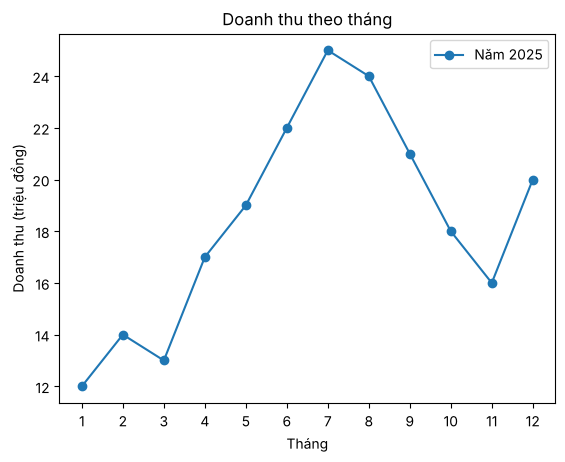

In [26]:
# ô plt_line
import matplotlib.pyplot as plt
thang = np.arange(1, 13)
doanh_thu = np.array([12, 14, 13, 17, 19, 22, 25, 24, 21, 18, 16, 20])
plt.plot(thang, doanh_thu, marker="o", color="tab:blue", label="Năm 2025")
plt.xlabel("Tháng")
plt.ylabel("Doanh thu (triệu đồng)")
plt.title("Doanh thu theo tháng")
plt.xticks(thang)
plt.legend()
plt.show()

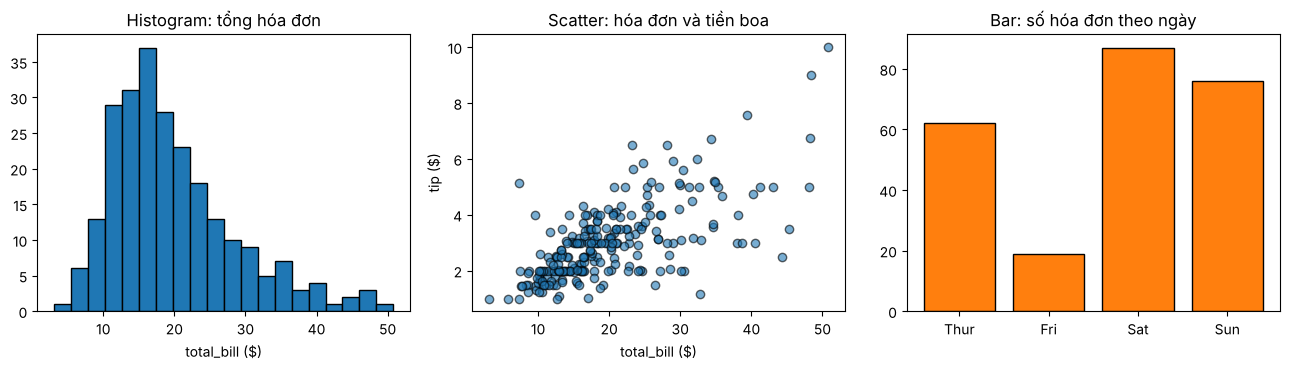

In [27]:
# ô plt_subplots
import seaborn as sns
tips = sns.load_dataset("tips")      # dữ liệu tiền boa ở một nhà hàng (244 hóa đơn)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].hist(tips["total_bill"], bins=20, color="tab:blue", edgecolor="k")
ax[0].set_title("Histogram: tổng hóa đơn")
ax[0].set_xlabel("total_bill ($)")
ax[1].scatter(tips["total_bill"], tips["tip"], alpha=0.6, edgecolors="k")
ax[1].set_title("Scatter: hóa đơn và tiền boa")
ax[1].set_xlabel("total_bill ($)"); ax[1].set_ylabel("tip ($)")
dem_ngay = tips["day"].value_counts().sort_index()
ax[2].bar(dem_ngay.index.astype(str), dem_ngay.values, color="tab:orange", edgecolor="k")
ax[2].set_title("Bar: số hóa đơn theo ngày")
plt.tight_layout()
plt.show()

In [28]:
# ô tips_head
print(tips.head())
print(tips.shape)

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
(244, 7)


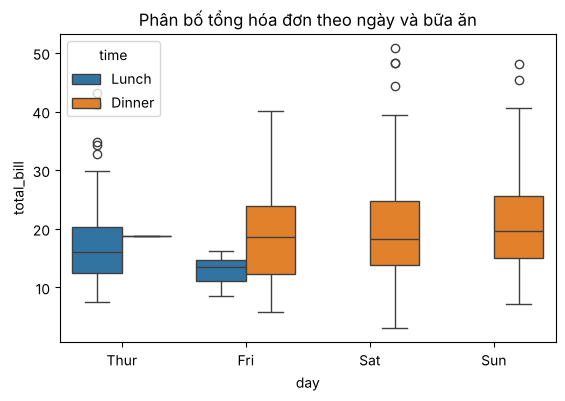

In [29]:
# ô sns_box
plt.figure(figsize=(6.4, 4))
sns.boxplot(data=tips, x="day", y="total_bill", hue="time")
plt.title("Phân bố tổng hóa đơn theo ngày và bữa ăn")
plt.show()

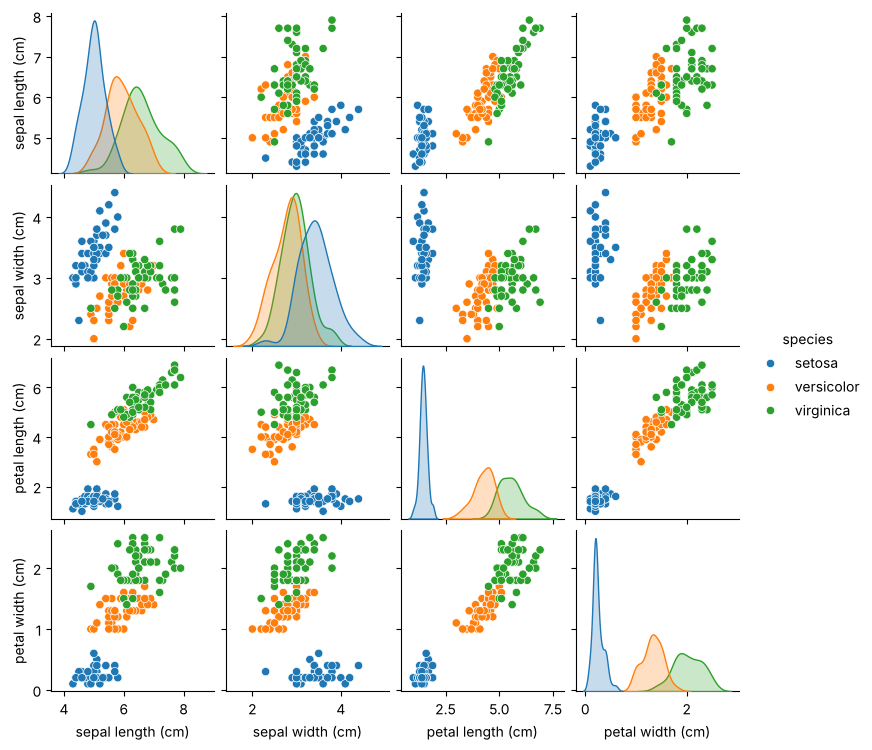

In [30]:
# ô sns_pair
from sklearn.datasets import load_iris
iris_df = load_iris(as_frame=True).frame
iris_df["species"] = iris_df["target"].map({0: "setosa", 1: "versicolor", 2: "virginica"})
sns.pairplot(iris_df.drop(columns="target"), hue="species", height=1.9)
plt.show()

            total_bill    tip   size
total_bill       1.000  0.676  0.598
tip              0.676  1.000  0.489
size             0.598  0.489  1.000


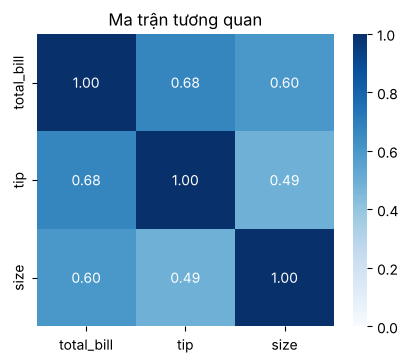

In [31]:
# ô sns_heatmap
tuong_quan = tips[["total_bill", "tip", "size"]].corr()
print(tuong_quan.round(3))
plt.figure(figsize=(4.8, 3.8))
sns.heatmap(tuong_quan, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Ma trận tương quan")
plt.show()

## 2.7 Làm quen với scikit-learn

In [32]:
# ô sk_datasets
from sklearn import datasets
for ten in ["load_iris", "load_wine", "load_breast_cancer", "load_digits", "load_diabetes"]:
    du_lieu = getattr(datasets, ten)()
    print(f"{ten:20s} X: {str(du_lieu.data.shape):10s} y: {du_lieu.target.shape}")

load_iris            X: (150, 4)   y: (150,)
load_wine            X: (178, 13)  y: (178,)
load_breast_cancer   X: (569, 30)  y: (569,)
load_digits          X: (1797, 64) y: (1797,)
load_diabetes        X: (442, 10)  y: (442,)


In [33]:
# ô sk_nhieu_mo_hinh
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

X, y = datasets.load_iris(return_X_y=True)          # trả về thẳng X, y dạng mảng NumPy
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

cac_mo_hinh = {
    "kNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Cây quyết định": DecisionTreeClassifier(random_state=42),
    "Hồi quy Logistic": LogisticRegression(max_iter=1000),
}
for ten, mo_hinh in cac_mo_hinh.items():
    mo_hinh.fit(X_train, y_train)                    # 1. học
    diem_so = mo_hinh.score(X_test, y_test)          # 2. chấm điểm (accuracy)
    print(f"{ten:18s}: accuracy = {diem_so:.4f}")

kNN (k=5)         : accuracy = 0.9778
Cây quyết định    : accuracy = 0.9333
Hồi quy Logistic  : accuracy = 0.9333


In [34]:
# ô sk_transformer
from sklearn.preprocessing import MinMaxScaler
du_lieu_nho = np.array([[1.0, 100.0],
                        [2.0, 300.0],
                        [3.0, 500.0]])
bo_bien_doi = MinMaxScaler()              # đưa mỗi cột về khoảng [0, 1]
bo_bien_doi.fit(du_lieu_nho)              # học min, max của từng cột
print("min mỗi cột:", bo_bien_doi.data_min_, " max mỗi cột:", bo_bien_doi.data_max_)
print(bo_bien_doi.transform(du_lieu_nho))

min mỗi cột: [  1. 100.]  max mỗi cột: [  3. 500.]
[[0.  0. ]
 [0.5 0.5]
 [1.  1. ]]


## Thực hành 2.1: Phân tích tiền boa

In [35]:
# ô lab_buoc1
tips = sns.load_dataset("tips")
tips["ti_le_boa"] = tips["tip"] / tips["total_bill"] * 100   # % tiền boa
print(tips[["total_bill", "tip", "ti_le_boa"]].describe().round(2))

       total_bill     tip  ti_le_boa
count      244.00  244.00     244.00
mean        19.79    3.00      16.08
std          8.90    1.38       6.11
min          3.07    1.00       3.56
25%         13.35    2.00      12.91
50%         17.80    2.90      15.48
75%         24.13    3.56      19.15
max         50.81   10.00      71.03


In [36]:
# ô lab_buoc2
print(tips.groupby("day", observed=True)["ti_le_boa"].mean().round(2))
print(tips.groupby("smoker", observed=True)["ti_le_boa"].mean().round(2))

day
Thur    16.13
Fri     16.99
Sat     15.32
Sun     16.69
Name: ti_le_boa, dtype: float64
smoker
Yes    16.32
No     15.93
Name: ti_le_boa, dtype: float64


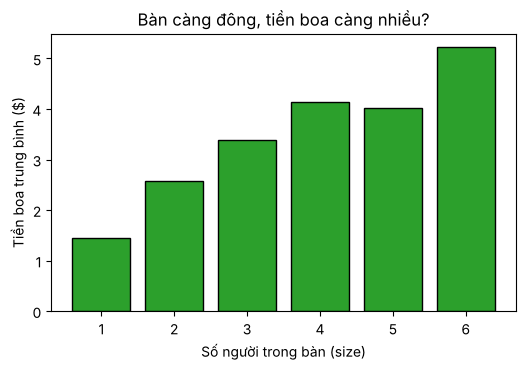

size
1    1.44
2    2.58
3    3.39
4    4.14
5    4.03
6    5.22
Name: tip, dtype: float64


In [37]:
# ô lab_buoc3
tb_size = tips.groupby("size")["tip"].mean()
plt.figure(figsize=(6, 3.6))
plt.bar(tb_size.index, tb_size.values, color="tab:green", edgecolor="k")
plt.xlabel("Số người trong bàn (size)")
plt.ylabel("Tiền boa trung bình ($)")
plt.title("Bàn càng đông, tiền boa càng nhiều?")
plt.show()
print(tb_size.round(2))

## Bài tập tự làm

Mức độ: ⭐ cơ bản, ⭐⭐ nâng cao, ⭐⭐⭐ thử thách. Viết lời giải vào ô mã trống ngay dưới mỗi bài.

**Bài 2.1.** ⭐ Tạo mảng NumPy gồm nhiệt độ 7 ngày trong tuần: `[31, 33, 30, 29, 34, 35, 32]`. Tính nhiệt độ trung bình, cao nhất, thấp nhất; đếm số ngày nóng hơn 32 độ; in ra các ngày (số thứ tự) có nhiệt độ trên trung bình.

In [ ]:
# Lời giải Bài 2.1


**Bài 2.2.** ⭐ Tạo ma trận $4 \times 3$ chứa điểm 3 môn của 4 sinh viên (tự chọn số liệu). Tính điểm trung bình của mỗi sinh viên và của mỗi môn. Sinh viên nào có điểm trung bình cao nhất? (Gợi ý: `np.argmax`.)

In [ ]:
# Lời giải Bài 2.2


**Bài 2.3.** ⭐ Với bảng `bang` trong Mục 2.5, hãy: (a) in các sinh viên tự học ít hơn 10 giờ; (b) thêm cột `dat` có giá trị `True` nếu cả hai môn đều từ 6,5 trở lên; (c) tính số giờ tự học trung bình của mỗi lớp.

In [ ]:
# Lời giải Bài 2.3


**Bài 2.4.** ⭐⭐ Với dữ liệu tips: (a) bữa trưa và bữa tối, bữa nào có tổng hóa đơn trung bình cao hơn? (b) vẽ histogram của cột `tip` với 25 khoảng; (c) vẽ biểu đồ phân tán giữa `total_bill` và `tip`, tô màu theo cột `time` bằng `sns.scatterplot`. Nêu nhận xét.

In [ ]:
# Lời giải Bài 2.4


**Bài 2.5.** ⭐⭐ Nạp bộ dữ liệu Penguins bằng `sns.load_dataset("penguins")`. Cho biết số dòng, số cột, kiểu dữ liệu từng cột và số ô trống của mỗi cột (gợi ý: `df.isna().sum()`). Vẽ `pairplot` tô màu theo loài (`species`) và cho biết cặp đặc trưng nào phân biệt các loài rõ nhất.

In [ ]:
# Lời giải Bài 2.5


**Bài 2.6.** ⭐⭐ Với bộ dữ liệu Wine, dùng pandas để tính trung bình của cột `alcohol` và `color_intensity` theo từng lớp. Vẽ boxplot của `proline` theo lớp. Đặc trưng `proline` có giúp phân biệt các lớp không?

In [ ]:
# Lời giải Bài 2.6


**Bài 2.7.** ⭐⭐⭐ Không dùng vòng lặp, chỉ dùng NumPy, hãy chuẩn hóa ma trận điểm ở Bài 2.2 sao cho mỗi cột có trung bình bằng 0: lấy mỗi phần tử trừ đi trung bình của cột chứa nó. Kiểm tra lại bằng `.mean(axis=0)`. Giải thích vì sao phép trừ thực hiện được dù hai mảng khác kích thước.

In [ ]:
# Lời giải Bài 2.7
